# 01 Revisión práctica de Machine Learning

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.


### Predicción inicial
Espero que las clases del dataset se encuentren desequilibradas, es decir que algunas especies de flores tengan más ejemplos que otras.
Creo que las medidas permitirán clasificar las flores al diferenciarlas por sus características similares.

In [2]:
from sklearn.datasets import load_iris
import pandas as pd
iris = load_iris()
x = iris.data
y = iris.target
df = pd.DataFrame(x, columns=[
    "largo_sepalo_cm",
    "ancho_sepalo_cm",
    "largo_petalo_cm",
    "ancho_petalo_cm",
])
df["especie"] = iris.target_names[y]


### ¿Qué representa cada instancia?

In [3]:
print(df.head(5))
print("Cada instancia representa las medidas de sépalo y pétalo de una flor junto con la especie a la que dicha flor pertenece.")

   largo_sepalo_cm  ancho_sepalo_cm  largo_petalo_cm  ancho_petalo_cm especie
0              5.1              3.5              1.4              0.2  setosa
1              4.9              3.0              1.4              0.2  setosa
2              4.7              3.2              1.3              0.2  setosa
3              4.6              3.1              1.5              0.2  setosa
4              5.0              3.6              1.4              0.2  setosa
Cada instancia representa las medidas de sépalo y pétalo de una flor junto con la especie a la que dicha flor pertenece.


### Número de instancias y características.

In [4]:
print("Número de instancias:",x.shape[0])
print("Número de caracteristicas:",x.shape[1])

Número de instancias: 150
Número de caracteristicas: 4


### Nombre y significado de cada característica.

In [5]:
print(iris.feature_names)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


Estas características hacen referencia a la longitud y ancho del sépalo en centímetros que es la parte que forman la parte más externa de la flor, también podemos encontrar la longitud y ancho de los pétalos en centímetros que son las hojas modificasdas que forman la corola de la flor.
A pesar de que los nombres se encuentran originalmente en inglés se las a cambiado a español en el DataFrame por facilidad de entendimiento.

### Clases y cantidad de ejemplos por clase.

In [6]:
print("Clases:", iris.target_names)
print(df["especie"].value_counts())

Clases: ['setosa' 'versicolor' 'virginica']
especie
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


### Dimensiones de la matriz de características y del vector de etiquetas.

In [7]:
print("Dimensiones de la matriz de características X:",x.shape)
print("Dimensiones del vector de etiquetas y:",y.shape)

Dimensiones de la matriz de características X: (150, 4)
Dimensiones del vector de etiquetas y: (150,)


Por lo tanto la matriz de características tiene una dimensión de 150 filas y 4 columnas, mientras que el vector de etiquetas tiene una etiqueta de especie para las 150 flores

### Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.

In [8]:
df.head(5)


,largo_sepalo_cm,ancho_sepalo_cm,largo_petalo_cm,ancho_petalo_cm,especie
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


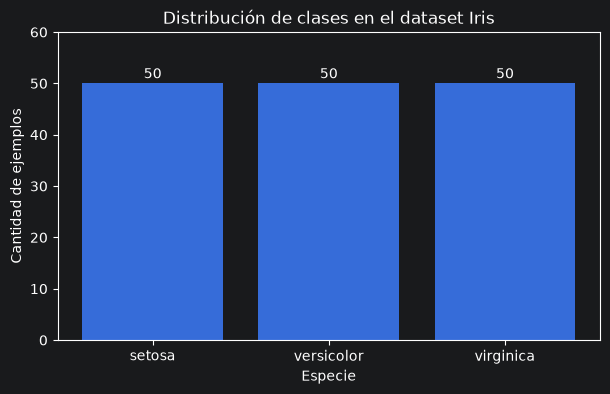

In [9]:
import matplotlib.pyplot as plt
conteo_clases = df["especie"].value_counts().reindex(iris.target_names)
plt.figure(figsize=(7, 4))
plt.bar(conteo_clases.index, conteo_clases.values)
plt.title("Distribución de clases en el dataset Iris")
plt.xlabel("Especie")
plt.ylabel("Cantidad de ejemplos")
plt.ylim(0, 60)
for posicion, cantidad in enumerate(conteo_clases.values):
    plt.text(posicion, cantidad + 1, str(cantidad), ha="center")
plt.show()

# 2. Comparación de clasificadores
## Predicciones iniciales
Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?
## Modelos
Construye un modelo de clasificación para la clase y compara:

* Gaussian Naive Bayes.
* Regresión logística multiclase.
* SVM lineal.
* Árbol de decisión.
* Random Forest.
* Gradient Boosting.
* MLP de clasificación.
* Usa características estandarizadas para los clasificadores.

### Predicciones iniciales
1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
Creo que regresión logística, SVM lineal y MLP de clasificación son modelos sensibles a las escalas de las características.
La regresión logística funciona gracias a una combinación de las características a través de pesos por lo que las escalas de dichas características afectan directamente a la clase predicha
SVM lineal por su parte determina el hiperplano capaz de separar a las clases por lo que la escala de las características afecta directamente a la distancia entre el hiperplano determinado y el punto, afectando a la clasificación que el modelo realiza.
MLP ajusta sus pesos mediante descenso de graidente, si las entradas están en escalas distintas el entrenamiento puede ser menos estable.
2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
Espero que el modelo de regresión logística multiclase sea el que produzca fornteras de decisión más simples dado que realiza separaciones lineales que son sencillas de interpretar.
3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?
El rendimiento de un modelo depende de la data, de los patrones y relaciones entre las características y las clases, cada modelo representa los datos de una manera distinta y puede generalizar mejor o no la estimación de la clase a la que pertenece.
### Modelos

Dividimos la dara en entrenamiento, validación y prueba

In [10]:
from sklearn.model_selection import train_test_split
# 60 % entrenamiento
x_train, x_temp, y_train, y_temp = train_test_split(
    x,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)
# 20 % validación y 20 % prueba
x_val, x_test, y_val, y_test = train_test_split(
    x_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)
print("Entrenamiento:", x_train.shape, y_train.shape)
print("Validación:", x_val.shape, y_val.shape)
print("Prueba:", x_test.shape, y_test.shape)

Entrenamiento: (90, 4) (90,)
Validación: (30, 4) (30,)
Prueba: (30, 4) (30,)


#### Gaussian Naive Bayes


In [12]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, f1_score
modelo_gnb = Pipeline([
    ("escalador", StandardScaler()),
    ("clasificador", GaussianNB())
])
modelo_gnb.fit(x_train, y_train)
pred_gnb_val = modelo_gnb.predict(x_val)

accuracy_gnb_val = accuracy_score(y_val, pred_gnb_val)
f1_gnb_val = f1_score(y_val, pred_gnb_val, average="macro")
print("Accuracy en validación:", accuracy_gnb_val)
print("F1 macro en validación:", f1_gnb_val)

Accuracy en validación: 0.9333333333333333
F1 macro en validación: 0.9333333333333332


#### Regresión logística multiclase

In [13]:
from sklearn.linear_model import LogisticRegression

modelo_logistico = Pipeline([
    ("escalador", StandardScaler()),
    ("clasificador", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])
modelo_logistico.fit(x_train, y_train)
pred_logistica_val = modelo_logistico.predict(x_val)
accuracy_logistica_val = accuracy_score(y_val, pred_logistica_val)
f1_logistica_val = f1_score(
    y_val,
    pred_logistica_val,
    average="macro"
)

print("Accuracy en validación:", accuracy_logistica_val)
print("F1 macro en validación:", f1_logistica_val)

Accuracy en validación: 0.9333333333333333
F1 macro en validación: 0.9333333333333332


#### SVM lineal

In [14]:
from sklearn.svm import SVC

modelo_svm = Pipeline([
    ("escalador", StandardScaler()),
    ("clasificador", SVC(
        kernel="linear",
        C=1.0
    ))
])
modelo_svm.fit(x_train, y_train)
pred_svm_val = modelo_svm.predict(x_val)
accuracy_svm_val = accuracy_score(y_val, pred_svm_val)
f1_svm_val = f1_score(
    y_val,
    pred_svm_val,
    average="macro"
)

print("Accuracy en validación:", accuracy_svm_val)
print("F1 macro en validación:", f1_svm_val)

Accuracy en validación: 0.9666666666666667
F1 macro en validación: 0.9665831244778612


#### Árbol de decisión

In [15]:
from sklearn.tree import DecisionTreeClassifier

modelo_arbol = Pipeline([
    ("escalador", StandardScaler()),
    ("clasificador", DecisionTreeClassifier(
        random_state=42
    ))
])

modelo_arbol.fit(x_train, y_train)
pred_arbol_val = modelo_arbol.predict(x_val)

accuracy_arbol_val = accuracy_score(y_val, pred_arbol_val)
f1_arbol_val = f1_score(
    y_val,
    pred_arbol_val,
    average="macro"
)

print("Accuracy en validación:", accuracy_arbol_val)
print("F1 macro en validación:", f1_arbol_val)

Accuracy en validación: 0.9333333333333333
F1 macro en validación: 0.9333333333333332


#### Random forest

In [17]:
from sklearn.ensemble import RandomForestClassifier

modelo_random_forest = Pipeline([
    ("escalador", StandardScaler()),
    ("clasificador", RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ))
])
modelo_random_forest.fit(x_train, y_train)
pred_rf_val = modelo_random_forest.predict(x_val)
accuracy_rf_val = accuracy_score(y_val, pred_rf_val)
f1_rf_val = f1_score(
    y_val,
    pred_rf_val,
    average="macro"
)

print("Accuracy en validación:", accuracy_rf_val)
print("F1 macro en validación:", f1_rf_val)

Accuracy en validación: 0.9333333333333333
F1 macro en validación: 0.9333333333333332


#### Gradient Boosting

In [19]:
from sklearn.ensemble import GradientBoostingClassifier

modelo_gradient_boosting = Pipeline([
    ("escalador", StandardScaler()),
    ("clasificador", GradientBoostingClassifier(
        random_state=42
    ))
])
modelo_gradient_boosting.fit(x_train, y_train)
pred_gb_val = modelo_gradient_boosting.predict(x_val)
accuracy_gb_val = accuracy_score(y_val, pred_gb_val)
f1_gb_val = f1_score(
    y_val,
    pred_gb_val,
    average="macro"
)
print("Accuracy en validación:", accuracy_gb_val)
print("F1 macro en validación:", f1_gb_val)

Accuracy en validación: 0.9333333333333333
F1 macro en validación: 0.9333333333333332


#### MLP

In [20]:
from sklearn.neural_network import MLPClassifier

modelo_mlp = Pipeline([
    ("escalador", StandardScaler()),
    ("clasificador", MLPClassifier(
        hidden_layer_sizes=(10,),
        max_iter=2000,
        random_state=42
    ))
])
modelo_mlp.fit(x_train, y_train)
pred_mlp_val = modelo_mlp.predict(x_val)
accuracy_mlp_val = accuracy_score(y_val, pred_mlp_val)
f1_mlp_val = f1_score(
    y_val,
    pred_mlp_val,
    average="macro"
)
print("Accuracy en validación:", accuracy_mlp_val)
print("F1 macro en validación:", f1_mlp_val)

Accuracy en validación: 0.9666666666666667
F1 macro en validación: 0.9665831244778612


### Comparación

In [21]:
resultados_iniciales = pd.DataFrame({
    "Modelo": [
        "Gaussian Naive Bayes",
        "Regresión logística",
        "SVM lineal",
        "Árbol de decisión",
        "Random Forest",
        "Gradient Boosting",
        "MLP"
    ],
    "Accuracy de validación": [
        accuracy_gnb_val,
        accuracy_logistica_val,
        accuracy_svm_val,
        accuracy_arbol_val,
        accuracy_rf_val,
        accuracy_gb_val,
        accuracy_mlp_val
    ],
    "F1 macro de validación": [
        f1_gnb_val,
        f1_logistica_val,
        f1_svm_val,
        f1_arbol_val,
        f1_rf_val,
        f1_gb_val,
        f1_mlp_val
    ]
})
resultados_iniciales.sort_values(
    by="F1 macro de validación",
    ascending=False
).reset_index(drop=True)

,Modelo,Accuracy de validación,F1 macro de validación
0,SVM lineal,0.966667,0.966583
1,MLP,0.966667,0.966583
2,Gaussian Naive Bayes,0.933333,0.933333
3,Regresión logística,0.933333,0.933333
4,Árbol de decisión,0.933333,0.933333
5,Random Forest,0.933333,0.933333
6,Gradient Boosting,0.933333,0.933333


Los modelos de SVM lineal y MLP tienen la mayor exactitud y F1 macro de validación, por lo que son los modelos que han obtenido el mayor porcentaje de clasificaciones correctas y mayor rendimiento F1 macro.

# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.

## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.

## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
3. ¿Cómo se interpreta un R² negativo?
4. ¿Qué efecto tuvo aumentar la regularización?
5. ¿Qué puede explicar los errores grandes?
6. ¿Un coeficiente predictivo demuestra una relación causal?

### Cargar dataset Diabetes

In [3]:
from sklearn.datasets import load_diabetes
import pandas as pd
diabetes = load_diabetes()

x_diabetes = diabetes.data
y_diabetes = diabetes.target

df_diabetes = pd.DataFrame(
    x_diabetes,
    columns=diabetes.feature_names
)
df_diabetes["progresion_enfermedad"] = y_diabetes
print("Dimensiones de x:", x_diabetes.shape)
print("Dimensiones de y:", y_diabetes.shape)
print("\nCaracterísticas:")
print(diabetes.feature_names)
df_diabetes.head()

Dimensiones de x: (442, 10)
Dimensiones de y: (442,)

Características:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progresion_enfermedad
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


### Predicción inicial
¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.
Espero que un modelo más flexible produzca una menor cantidad de errores ante datos nuevos, sin embargo no siempre, un modelo extremadamente flexible causará overfitting por lo que fallaría en generalizar y por ende se espera falle al ingresar nuevos datos.